# Análise exploratória: enchentes em Porto Alegre

Projeto extensionista CPAD. Este notebook explora os dados limpos da simulação do INCT SiMAI (Tela 1) e as bases externas (Tela 2).

Para rodar: `python scripts/limpeza_inct.py` antes deste notebook. Os dados de entrada ficam em `dados/processados/`; a origem de cada um está em `dados/README.md`.

Os gráficos também são salvos em `notebooks/figs/` e usados no relatório de limpeza.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

PROC = Path('../dados/processados')
ORIG = Path('../dados/originais')
FIGS = Path('figs'); FIGS.mkdir(exist_ok=True)

plt.rcParams.update({'figure.figsize': (9, 4.8), 'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'font.size': 10})
AZUL, LARANJA, VERDE, CINZA, VERMELHO, ROXO = '#2160A8', '#D97A1E', '#2A8C7A', '#8C96A1', '#C2362B', '#6B4FA0'
milhar = FuncFormatter(lambda v, _: f'{v:,.0f}'.replace(',', '.'))

def salvar(nome):
    plt.tight_layout()
    plt.savefig(FIGS / f'{nome}.png', dpi=170, bbox_inches='tight')
    plt.show()

df = pd.read_csv(PROC / '1_simulacao_inct/inct_longo_limpo.csv')
alt = pd.read_csv(PROC / '1_simulacao_inct/inct_alteracoes.csv')
print(df.shape, df.nivel_m.nunique(), 'níveis,', df.bairro.nunique(), 'bairros')
df.head()

(6674, 12) 71 níveis, 94 bairros


,nivel_m,bairro,bairro_malha,affected_buildings,total_buildings,percentage,population,affected_population,affected_buildings_original,percentage_original,affected_population_original,alterado
0,3.0,Aberta dos Morros,Aberta dos Morros,0,4696,0.00,9854,0,0,0,0,False
1,3.0,Agronomia,Agronomia,0,1771,0.00,2677,0,0,0,0,False
2,3.0,Anchieta,Anchieta,28,589,4.75,791,38,28,5,40,False
3,3.0,Arquipélago,Arquipélago,4685,4688,99.94,6411,6407,4685,100,6411,False
4,3.0,Auxiliadora,Auxiliadora,0,1995,0.00,8909,0,0,0,0,False


## Parte 1: simulação do INCT (Tela 1)

### Gráfico 1: população afetada por nível, antes e depois da limpeza

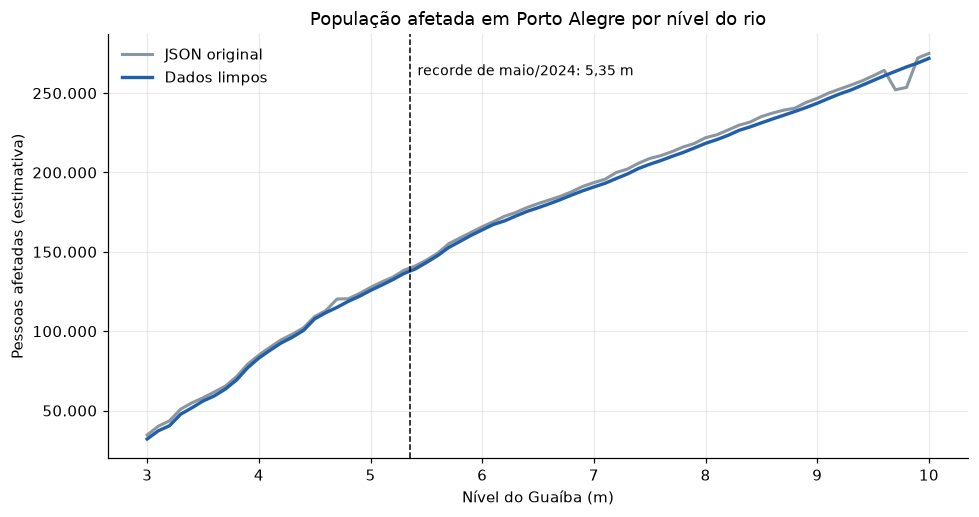

         affected_population_original  affected_population
nivel_m                                                   
3.0                             34605                32119
5.3                            138414               136389
9.6                            264338               260917
9.7                            252080               263710
9.8                            253627               266519
10.0                           274993               271886


In [2]:
tot = df.groupby('nivel_m')[['affected_population_original', 'affected_population']].sum()
fig, ax = plt.subplots()
ax.plot(tot.index, tot.affected_population_original, color=CINZA, lw=2, label='JSON original')
ax.plot(tot.index, tot.affected_population, color=AZUL, lw=2.2, label='Dados limpos')
ax.axvline(5.35, color='k', ls='--', lw=1); ax.text(5.42, tot.max().max() * 0.95, 'recorde de maio/2024: 5,35 m', fontsize=9)
ax.yaxis.set_major_formatter(milhar); ax.set_xlabel('Nível do Guaíba (m)'); ax.set_ylabel('Pessoas afetadas (estimativa)')
ax.set_title('População afetada em Porto Alegre por nível do rio'); ax.legend(frameon=False)
salvar('g1_curva_populacao')
print(tot.loc[[3.0, 5.3, 9.6, 9.7, 9.8, 10.0]])

**Comentário.** No JSON original a curva cai de 264.338 para 252.080 pessoas ao passar de 9,6 para 9,7 m, o que é fisicamente impossível. O motivo é que o Centro Histórico aparece com zero prédios afetados em 9,7 e 9,8 m. Depois da limpeza a curva só sobe. O recorde de 5,35 m fica entre os níveis simulados de 5,3 e 5,4 m. A 5,3 m a estimativa passa de 138.414 para 136.389 pessoas. Essa diferença vem de o arquivo arredondar a porcentagem para cima.

### Gráfico 2: séries que violam a regra física

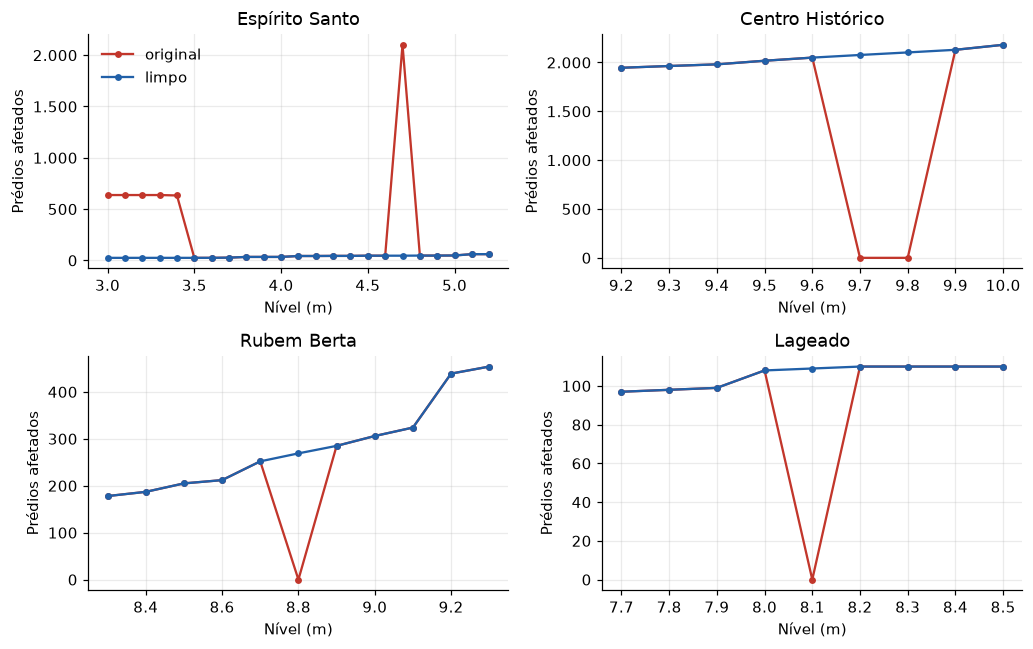

regra
bloco inicial incompatível: primeiro valor plausível     5
monotonia: máximo acumulado                             65
pico isolado: interpolação linear                        1
zero isolado: interpolação linear                        4
dtype: int64


In [3]:
casos = {'Espírito Santo': (3.0, 5.2), 'Centro Histórico': (9.2, 10.0), 'Rubem Berta': (8.3, 9.3), 'Lageado': (7.7, 8.5)}
fig, axes = plt.subplots(2, 2, figsize=(9.5, 6))
for ax, (b, (a, z)) in zip(axes.ravel(), casos.items()):
    s = df[(df.bairro == b) & df.nivel_m.between(a, z)]
    ax.plot(s.nivel_m, s.affected_buildings_original, color=VERMELHO, marker='o', ms=3.5, label='original')
    ax.plot(s.nivel_m, s.affected_buildings, color=AZUL, marker='o', ms=3.5, label='limpo')
    ax.set_title(b); ax.set_xlabel('Nível (m)'); ax.set_ylabel('Prédios afetados'); ax.yaxis.set_major_formatter(milhar)
axes[0, 0].legend(frameon=False)
salvar('g2_series_inconsistentes')
print(alt.groupby('regra').size())

**Comentário.** Com o rio mais alto, um bairro não pode ter menos prédios afetados. O teste achou quatro bairros com problemas graves: zeros isolados no meio da série (Centro Histórico, Rubem Berta, Lageado) e, no Espírito Santo, um bloco inicial de cerca de 637 prédios que cai para 25, mais um pico de 2.101 em 4,7 m. Os zeros e o pico foram interpolados. O bloco inicial recebeu o primeiro valor plausível (25, em 3,5 m).

### Gráfico 3: efeito do arredondamento da porcentagem

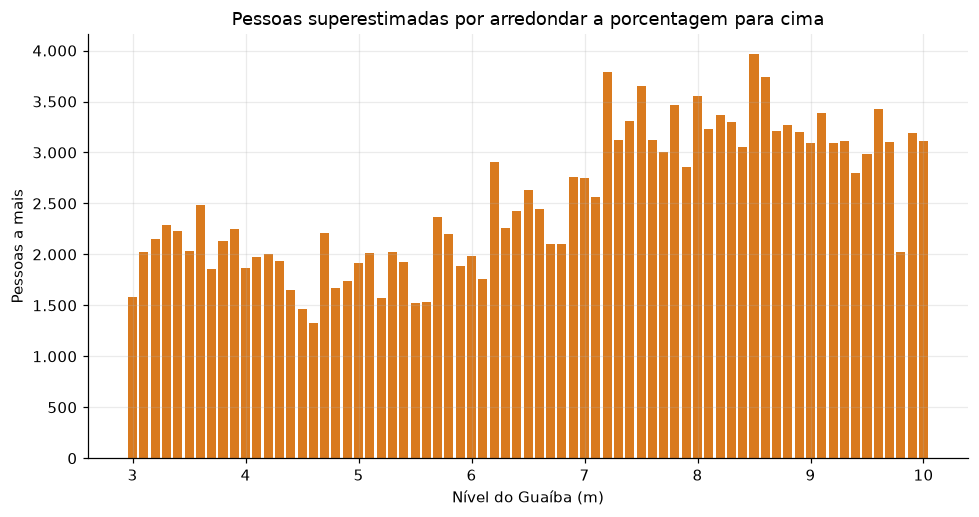

excesso: mín 1328 máx 3963 | % do total a 3,0 m: 4.8 | a 5,3 m: 1.5


In [4]:
# Compara o campo original com o valor exato calculado a partir dos prédios originais.
exato = df.population * df.affected_buildings_original / df.total_buildings
exc = (df.affected_population_original - exato).groupby(df.nivel_m).sum()
base = df.assign(exato=exato).groupby('nivel_m').exato.sum()
fig, ax = plt.subplots()
ax.bar(exc.index, exc.values, width=.08, color=LARANJA)
ax.yaxis.set_major_formatter(milhar); ax.set_xlabel('Nível do Guaíba (m)'); ax.set_ylabel('Pessoas a mais')
ax.set_title('Pessoas superestimadas por arredondar a porcentagem para cima')
salvar('g3_arredondamento')
print('excesso: mín', round(exc.min()), 'máx', round(exc.max()), '| % do total a 3,0 m:', round(exc[3.0]/base[3.0]*100, 1), '| a 5,3 m:', round(exc[5.3]/base[5.3]*100, 1))

**Comentário.** O campo `percentage` é o teto inteiro da porcentagem real, e `affected_population` é calculado a partir dele. Um bairro com 0,2% dos prédios afetados entra com 1% da população. O efeito pesa mais em níveis baixos, quando muitos bairros têm poucos prédios atingidos. Por isso os dois campos foram recalculados a partir dos prédios.

### Gráfico 4: bairros mais atingidos a 5,3 m, logo abaixo do recorde

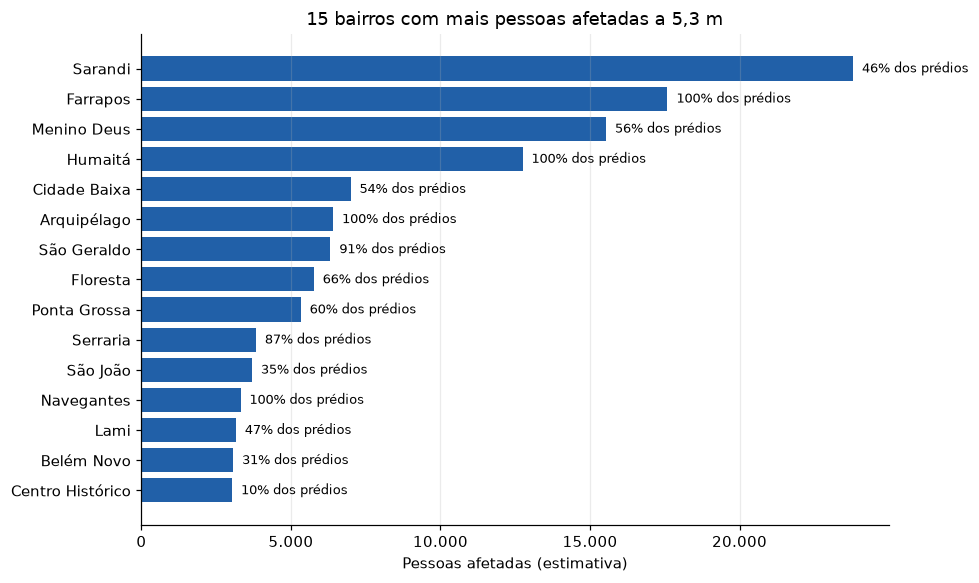

36 bairros atingidos a 5,3 m; 40 nunca atingidos


In [5]:
n53 = df[df.nivel_m == 5.3].sort_values('affected_population', ascending=False).head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5.4))
ax.barh(n53.bairro, n53.affected_population, color=AZUL)
for y, (p, pc) in enumerate(zip(n53.affected_population, n53.percentage)):
    ax.text(p + 300, y, f'{pc:.0f}% dos prédios', va='center', fontsize=8.5)
ax.xaxis.set_major_formatter(milhar); ax.set_xlabel('Pessoas afetadas (estimativa)'); ax.set_title('15 bairros com mais pessoas afetadas a 5,3 m'); ax.grid(axis='y', visible=False)
salvar('g4_ranking_53')
print((df[df.nivel_m == 5.3].affected_buildings > 0).sum(), 'bairros atingidos a 5,3 m;', (df.groupby('bairro').affected_buildings.max() == 0).sum(), 'nunca atingidos')

**Comentário.** Número de pessoas e porcentagem de prédios contam histórias diferentes. Sarandi lidera em pessoas sem estar entre os bairros com maior porcentagem de prédios, enquanto Farrapos, Humaitá, Arquipélago e Navegantes aparecem totalmente atingidos. Por isso a Tela 1 mostra os dois: porcentagem por bairro e ranking de pessoas.

## Parte 2: verba da reconstrução (Tela 2)

As bases da Prefeitura mostram para onde vai o recurso. Os empenhos do TCE-RS não entram nos totais, porque não há um marcador oficial que identifique toda a despesa da enchente. Os valores por obra são **previstos**, não pagos, e 38% deles se repetem (rateio ou valor-padrão), por isso servem para mostrar direção e ordem de grandeza, não custo exato.

### Gráfico 5: necessidade estimada, solicitado e recebido

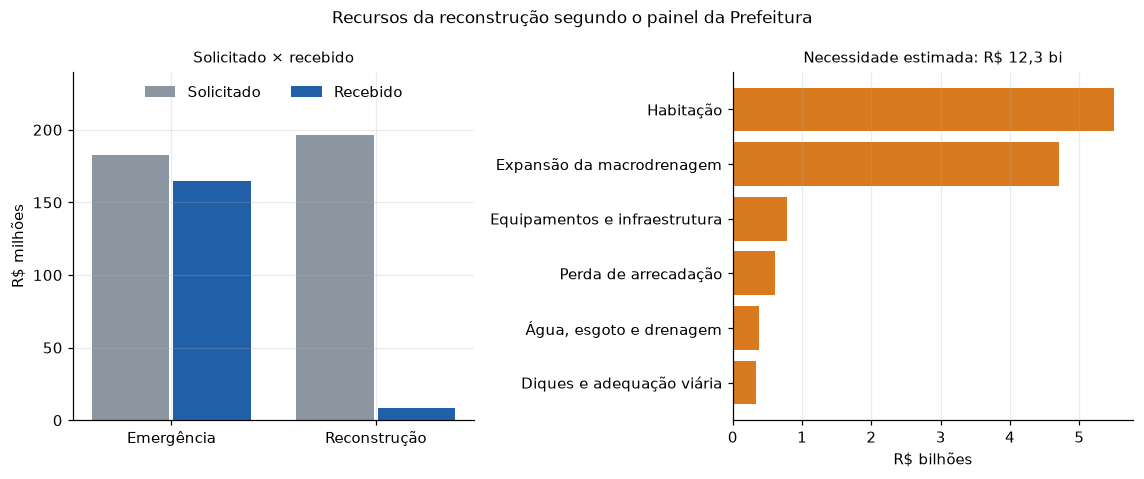

recurso                     Recebido  Solicitado
gráfico                                         
Demais Despesas Emergência     164.4       182.8
Reconstrução                     8.4       196.6
                         nome   bi
    Diques e adequação viária 0.34
      Água, esgoto e drenagem 0.38
         Perda de arrecadação 0.60
Equipamentos e infraestrutura 0.78
    Expansão da macrodrenagem 4.70
                    Habitação 5.50


In [6]:
fin = pd.DataFrame([x['attributes'] for x in json.load(open(ORIG / '3_investimento_reconstrucao/hub_base_financeiro_2_recursos.json', encoding='utf-8'))['features']])
f = fin[fin['recurso'].notna() & fin['gráfico'].isin(['Reconstrução', 'Demais Despesas Emergência'])].copy(); f['mi'] = f.valor.astype(float) / 1e6
pv = f.pivot(index='gráfico', columns='recurso', values='mi').loc[['Demais Despesas Emergência', 'Reconstrução']]
curtos = {'equipamentos': 'Equipamentos e infraestrutura', 'habita': 'Habitação', 'abastecimento': 'Água, esgoto e drenagem',
          'diques': 'Diques e adequação viária', 'arrecada': 'Perda de arrecadação', 'macrodrenagem': 'Expansão da macrodrenagem'}
dem = fin[fin.demanda.notna()].copy(); dem['bi'] = dem.valor.astype(float) / 1e9
dem['nome'] = dem.demanda.map(lambda t: next(v for k, v in curtos.items() if k in t.lower())); dem = dem.sort_values('bi')
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4))
x = np.arange(2); axes[0].bar(x - .2, pv['Solicitado'], .38, color=CINZA, label='Solicitado'); axes[0].bar(x + .2, pv['Recebido'], .38, color=AZUL, label='Recebido')
axes[0].set_xticks(x, ['Emergência', 'Reconstrução']); axes[0].set_ylabel('R$ milhões'); axes[0].set_ylim(0, 240); axes[0].legend(frameon=False, ncol=2, loc='upper center'); axes[0].set_title('Solicitado × recebido', fontsize=10)
axes[1].barh(dem.nome, dem.bi, color=LARANJA); axes[1].set_xlabel('R$ bilhões'); axes[1].set_title(f'Necessidade estimada: R$ {dem.bi.sum():.1f} bi'.replace('.', ','), fontsize=10); axes[1].grid(axis='y', visible=False)
fig.suptitle('Recursos da reconstrução segundo o painel da Prefeitura', fontsize=11)
salvar('g5_recurso')
print(pv.round(1)); print(dem[['nome', 'bi']].round(2).to_string(index=False))

**Comentário.** A Prefeitura estima em R$ 12,3 bi o prejuízo da enchente ao setor público, principalmente em habitação e expansão da macrodrenagem, valor que inclui também a perda de arrecadação. O painel registra como recebida quase toda a verba solicitada para emergência (R$ 164,4 mi de R$ 182,8 mi), mas só R$ 8,4 mi dos R$ 196,6 mi solicitados para reconstrução, cerca de 4%. Segundo o texto do painel, os pedidos foram feitos à União por cadastros formais, como os da Defesa Civil e do Ministério da Saúde. As despesas pagas registradas no TCE-RS não aparecem aqui: sem um marcador oficial da enchente, qualquer total dependeria de um filtro por palavras que erra para mais e para menos.

### Gráfico 6: investimento previsto por tipo de obra

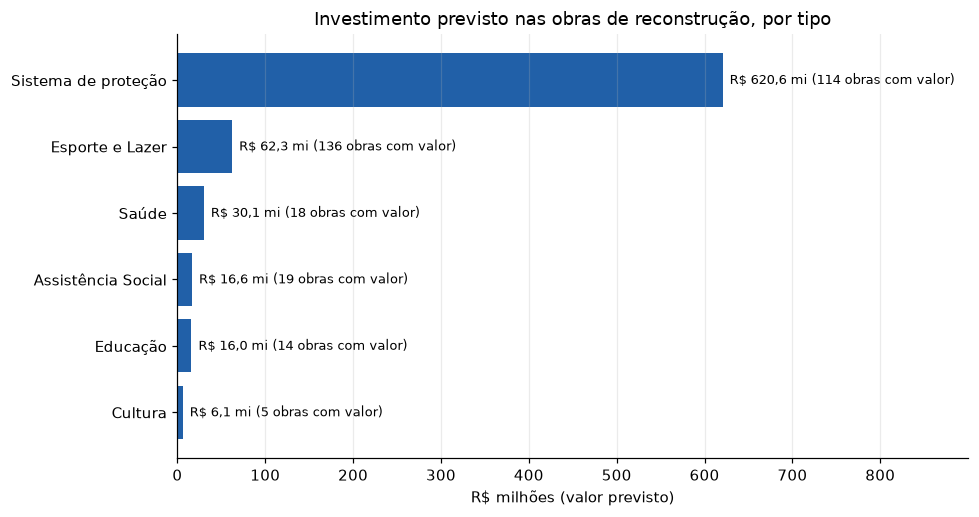

                     count     mi
tipo                             
Cultura                  5    6.1
Educação                14   16.0
Assistência Social      19   16.6
Saúde                   18   30.1
Esporte e Lazer        136   62.3
Sistema de proteção    114  620.6
total obras: 751,7 | habitação (necessidade estimada): 1.957,3


In [7]:
O3 = ORIG / '3_investimento_reconstrucao'
obras = pd.DataFrame([x['attributes'] for x in json.load(open(O3 / 'base_reconstrucao_3_infraestrutura.json', encoding='utf-8'))['features']])
obras['tipo'] = obras.tema.fillna('Sistema de proteção')
prev = obras.groupby('tipo').valor_invest.agg(['count', 'sum']).sort_values('sum')
prev['mi'] = prev['sum'] / 1e6
reais = lambda v: f'{v:,.1f}'.replace(',', 'X').replace('.', ',').replace('X', '.')
fig, ax = plt.subplots()
ax.barh(prev.index, prev.mi, color=AZUL)
for y, (mi, n) in enumerate(zip(prev.mi, prev['count'])):
    ax.text(mi + 8, y, f'R$ {reais(mi)} mi ({int(n)} obras com valor)', va='center', fontsize=8.5)
ax.set_xlim(0, prev.mi.max() * 1.45); ax.set_xlabel('R$ milhões (valor previsto)'); ax.grid(axis='y', visible=False)
ax.set_title('Investimento previsto nas obras de reconstrução, por tipo')
salvar('g6_previsto_por_tipo')
hab = pd.DataFrame([x['attributes'] for x in json.load(open(O3 / 'hub_habitacao_1_demhab.json', encoding='utf-8'))['features']])
print(prev[['count', 'mi']].round(1)); print('total obras:', reais(prev.mi.sum()), '| habitação (necessidade estimada):', reais(hab.investim_03.sum() / 1e6))

**Comentário.** O sistema de proteção (diques, casas de bombas e comportas) concentra R$ 620,6 mi dos R$ 751,7 mi previstos nas obras, cerca de 83%. As obras de esporte e lazer são as mais numerosas, mas somam bem menos. A habitação não entra no gráfico porque o valor do DEMHAB é uma necessidade estimada de reposição (R$ 1,96 bi nas 120 áreas), de natureza diferente do previsto por obra.

### Gráfico 7: situação das obras por tipo

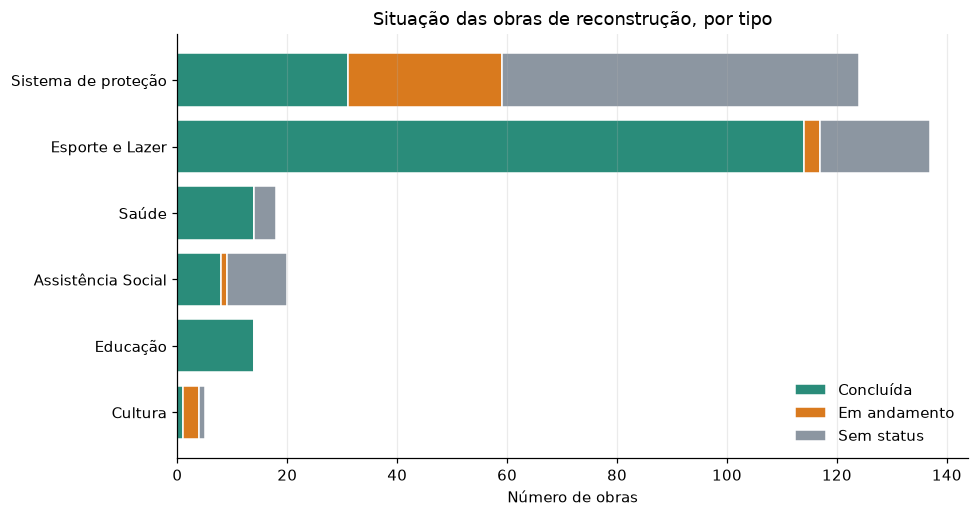

obra_status          Concluída  Em andamento  Sem status
tipo                                                    
Cultura                      1             3           1
Educação                    14             0           0
Assistência Social           8             1          11
Saúde                       14             0           4
Esporte e Lazer            114             3          20
Sistema de proteção         31            28          65


In [8]:
st = pd.crosstab(obras.tipo, obras.obra_status.fillna('SEM STATUS').str.capitalize()).loc[prev.index]
cores_st = {'Concluída': VERDE, 'Em andamento': LARANJA, 'Sem status': CINZA}
fig, ax = plt.subplots()
esq = np.zeros(len(st))
for col in ['Concluída', 'Em andamento', 'Sem status']:
    ax.barh(st.index, st[col], left=esq, color=cores_st[col], label=col, edgecolor='white', linewidth=1)
    esq += st[col].values
ax.set_xlabel('Número de obras'); ax.legend(frameon=False, loc='lower right'); ax.grid(axis='y', visible=False)
ax.set_title('Situação das obras de reconstrução, por tipo')
salvar('g7_situacao_obras')
print(st)

**Comentário.** A maioria das obras de equipamentos públicos aparece como concluída (151 de 194). No sistema de proteção é o contrário: das 124 obras, só 31 constam como concluídas, 28 estão em andamento e 65 não têm situação informada. A base não informa a data de cada situação, então este é um retrato da exportação de 17/09/2026, não necessariamente da situação de hoje.

### Gráfico 8: onde estão as obras

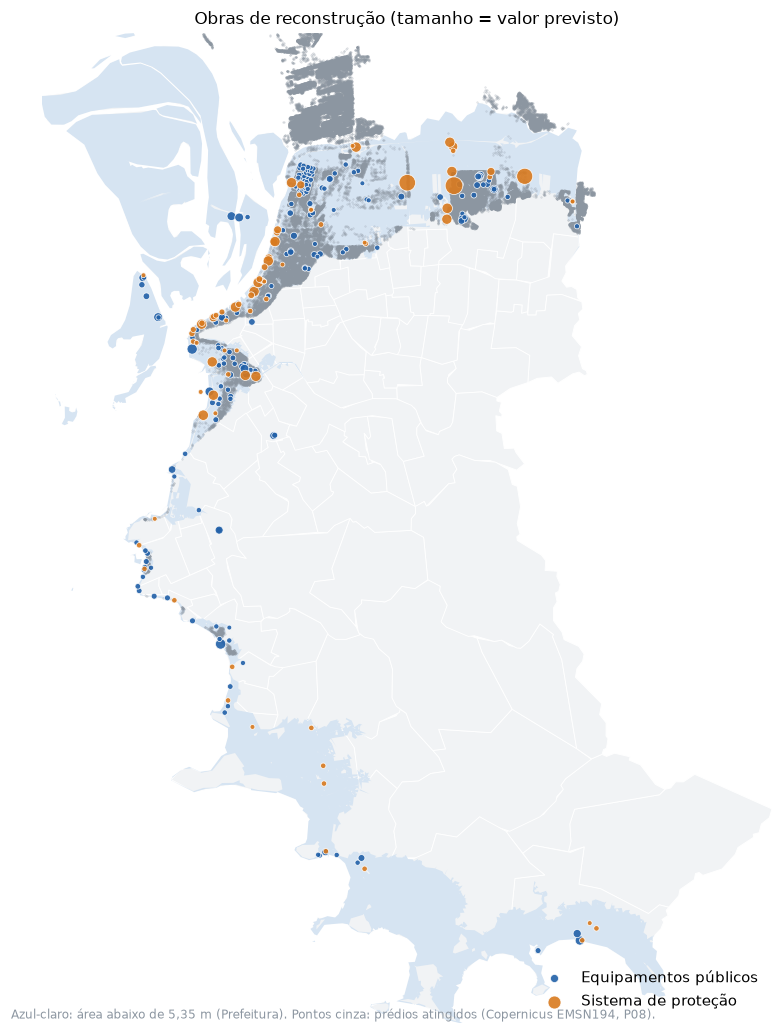

274 obras com localização; 265 a até 50 m da área abaixo de 5,35 m


In [9]:
import geopandas as gpd
bairros = gpd.read_file(ORIG / 'comum/bairros.geojson')
cota = gpd.read_file(ORIG / 'comum/cotas_inunda_5_35_limite_muni.geojson')
p08 = pd.concat([gpd.read_file(f) for f in sorted((ORIG / 'comum/copernicus_p08').glob('*.geojson'))])
xmin, ymin, xmax, ymax = bairros.total_bounds
p08 = p08.cx[xmin:xmax, ymin:ymax]
com_local = obras.dropna(subset=['latitude'])
pts = gpd.GeoDataFrame(com_local, geometry=gpd.points_from_xy(com_local.longitude, com_local.latitude), crs=4326)
fig, ax = plt.subplots(figsize=(7.5, 9.5))
bairros.plot(ax=ax, color='#F1F3F5', edgecolor='white', linewidth=.6)
cota.plot(ax=ax, color='#D6E4F2', linewidth=0)
p08.plot(ax=ax, color=CINZA, markersize=.15, alpha=.35)
for dash, cor, nome in [('Infraestrutura', AZUL, 'Equipamentos públicos'), ('Sistema de Prevenção', LARANJA, 'Sistema de proteção')]:
    g = pts[pts.dash == dash]
    ax.scatter(g.geometry.x, g.geometry.y, s=10 + np.sqrt(g.valor_invest.fillna(0) / 1e4), color=cor, edgecolor='white', linewidth=.5, alpha=.9, label=nome, zorder=3)
ax.set_xlim(xmin, xmax); ax.set_ylim(ymin, ymax); ax.set_axis_off(); ax.legend(frameon=False, loc='lower right')
ax.set_title('Obras de reconstrução (tamanho = valor previsto)', fontsize=11)
fig.text(.02, .02, 'Azul-claro: área abaixo de 5,35 m (Prefeitura). Pontos cinza: prédios atingidos (Copernicus EMSN194, P08).', fontsize=8, color=CINZA)
salvar('g8_mapa_obras')
proj = pts.to_crs(31982)
area = cota.to_crs(31982).make_valid().union_all().buffer(50)
print(len(pts), 'obras com localização;', int(proj.within(area).sum()), 'a até 50 m da área abaixo de 5,35 m')

**Comentário.** Das 274 obras com localização, 265 ficam a até 50 m da área do terreno abaixo da cota de 5,35 m, ou seja, nas áreas baixas da cidade, como se espera. Essa área é a cota oficial da Prefeitura, diferente da mancha do INCT usada no Gráfico 9, por isso os números não são iguais. Elas se concentram na faixa norte, no Centro e no Arquipélago, que também têm muitos prédios marcados pelo Copernicus. O tamanho dos pontos usa o valor previsto e deve ser lido como ordem de grandeza.

### Gráfico 9: investimento exposto, nível a nível (base do slider da Tela 2)

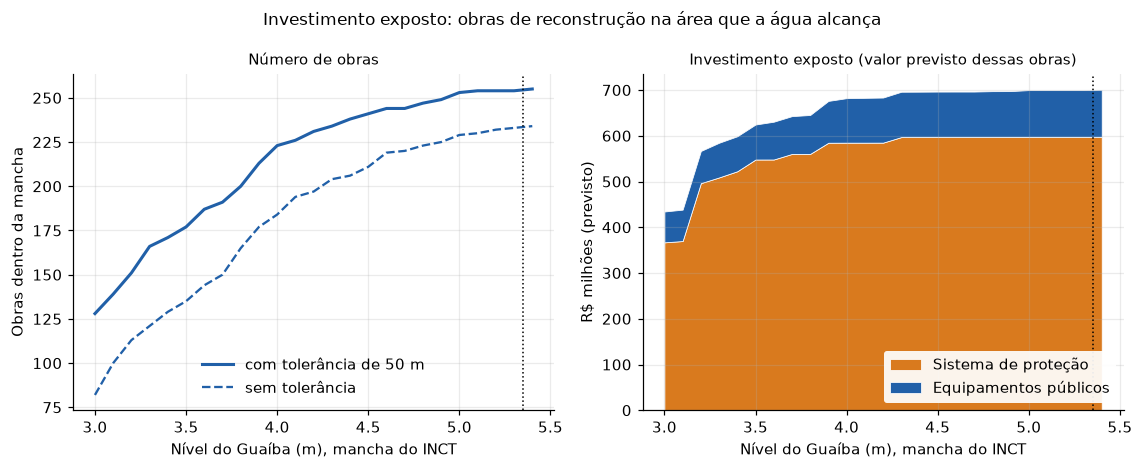

         obras  obras_sem_tolerancia  previsto_sistema_protecao_mi  \
nivel_m                                                              
3.0        128                    82                        367.05   
3.5        177                   135                        548.09   
4.0        223                   184                        584.93   
5.0        253                   229                        597.27   
5.4        255                   234                        597.27   

         previsto_equipamentos_mi  
nivel_m                            
3.0                         67.41  
3.5                         76.52  
4.0                         97.30  
5.0                        102.57  
5.4                        103.40  


In [10]:
niv = pd.read_csv(PROC / '3_investimento_reconstrucao/obras_por_nivel.csv')
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.3))
axes[0].plot(niv.nivel_m, niv.obras, color=AZUL, lw=2, label='com tolerância de 50 m')
axes[0].plot(niv.nivel_m, niv.obras_sem_tolerancia, color=AZUL, lw=1.5, ls='--', label='sem tolerância')
axes[0].set_ylabel('Obras dentro da mancha'); axes[0].set_title('Número de obras', fontsize=10); axes[0].legend(frameon=False)
axes[1].stackplot(niv.nivel_m, niv.previsto_sistema_protecao_mi, niv.previsto_equipamentos_mi, colors=[LARANJA, AZUL],
                  labels=['Sistema de proteção', 'Equipamentos públicos'], edgecolor='white', linewidth=.5)
axes[1].set_ylabel('R$ milhões (previsto)'); axes[1].set_title('Investimento exposto (valor previsto dessas obras)', fontsize=10); axes[1].legend(frameon=True, framealpha=.92, edgecolor='none', loc='lower right')
for ax in axes:
    ax.axvline(5.35, color='k', ls=':', lw=1); ax.set_xlabel('Nível do Guaíba (m), mancha do INCT')
fig.suptitle('Investimento exposto: obras de reconstrução na área que a água alcança', fontsize=11)
salvar('g9_obras_por_nivel')
print(niv.set_index('nivel_m').loc[[3.0, 3.5, 4.0, 5.0, 5.4], ['obras', 'obras_sem_tolerancia', 'previsto_sistema_protecao_mi', 'previsto_equipamentos_mi']])

**Comentário.** O investimento exposto é a soma do valor previsto das obras que ficam na área alcançada pela água. Não é custo de dano: mostra quanto da verba da reconstrução está indo para lugares que alagam. Com o rio a 3,0 m, a mancha do INCT já alcança 128 obras e R$ 434,5 mi de investimento exposto. A 4,0 m são 223 obras e R$ 682,2 mi, e a partir daí a curva quase para: a 5,4 m são 255 obras e R$ 700,7 mi, cerca de 95% do previsto nas obras com localização. O sistema de proteção domina o valor porque fica na beira do rio. A parte mais informativa são os equipamentos públicos, como escolas, praças e unidades de saúde: 89 obras e R$ 67,4 mi previstos já estão na área alcançada a 3,0 m. A contagem depende da tolerância de 50 m usada para compensar a localização por ponto e a mancha simplificada: sem tolerância, são 82 obras a 3,0 m e 234 a 5,4 m.

## Síntese para o dashboard

- **Tela 1:** usar os dados limpos, com a curva monótona e a porcentagem exata.
- **Tela 2:** um slider de 3,0 a 5,4 m mostra as obras na área que a água alcança e o investimento exposto, com tipo, local e situação de cada obra, e compara o previsto com o solicitado e o recebido. O TCE-RS entra só para ligar obras específicas a seus contratos.
- Os valores por obra são previsões e rateios (ver `dados/processados/auditoria_base_reconstrucao.md`). Somas por bairro ou por área só como ordem de grandeza, sempre com o rótulo "previsto".